In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor



In [5]:
# Locate the project folder.
root = Path.cwd().parent

# Load the preprocessed ML dataset.
ml_data = pd.read_csv(root / "data/processed/ml_data.csv")

# Define our predictors and target.
features = [
    "population_growth_lag1",
    "approvals_lag1",
    "cash_rate_lag1"
]

target = "price_growth_pct"

print("Dataset shape:", ml_data.shape)
display(ml_data.head())

Dataset shape: (72, 10)


,year,city,median_price_aud,price_growth_pct,population_growth_pct,approvals_per_1000,population_growth_lag1,approvals_lag1,cash_rate_pct,cash_rate_lag1
0,2017,Adelaide,450000.0,2.272727,1.073443,7.299723,0.809947,7.973977,1.522500,1.960000
1,2018,Adelaide,468000.0,4.000000,1.150142,8.123150,1.073443,7.299723,1.500000,1.522500
2,2019,Adelaide,478500.0,2.243590,1.385279,6.632110,1.150142,8.123150,1.481667,1.500000
3,2020,Adelaide,487500.0,1.880878,1.482133,7.304946,1.385279,6.632110,0.663333,1.481667
4,2021,Adelaide,550000.0,12.820513,0.654602,8.202603,1.482133,7.304946,0.150833,0.663333


In [6]:
# Split chronologically.
train = ml_data[ml_data["year"] <= 2022].copy()
test = ml_data[ml_data["year"] >= 2023].copy()

X_train = train[features]
X_test = test[features]

y_train = train[target]
y_test = test[target]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 48
Testing observations: 24


We establish a baseline model that predicts the average annual house-price growth observed during the training period.

This provides a simple benchmark against which we can evaluate more sophisticated regression models.

Evaluation: We use MAE, RMSE, and R² to measure predictive performance on the unseen 2023–2025 test period.

MAE and RMSE are measured in percentage points because our target is annual house-price growth (%).

In [7]:
# Use the training average as our baseline prediction.
baseline_prediction = np.full(len(y_test), y_train.mean())

# Evaluate the baseline.
baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction))
baseline_r2 = r2_score(y_test, baseline_prediction)

print(f"Training average growth: {y_train.mean():.2f}%")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Baseline R²: {baseline_r2:.3f}")

Training average growth: 7.02%
Baseline MAE: 6.53
Baseline RMSE: 8.11
Baseline R²: -0.160


In [9]:
# Train the linear regression model.
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict house-price growth on unseen years.
linear_prediction = linear_model.predict(X_test)

# Evaluate model performance.
linear_mae = mean_absolute_error(y_test, linear_prediction)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_prediction))
linear_r2 = r2_score(y_test, linear_prediction)

print(f"Linear Regression MAE: {linear_mae:.2f}")
print(f"Linear Regression RMSE: {linear_rmse:.2f}")
print(f"Linear Regression R²: {linear_r2:.3f}")

Linear Regression MAE: 20.17
Linear Regression RMSE: 21.65
Linear Regression R²: -7.262


In [10]:
# Examine the model's learned coefficients.
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": linear_model.coef_
})

display(coefficients.round(3))

print("Intercept:", round(linear_model.intercept_, 3))

# Compare economic conditions between training and testing.
for feature in features:
    print(f"\n{feature}")
    print("Train range:", X_train[feature].min().round(2),
          "to", X_train[feature].max().round(2))
    print("Test range:", X_test[feature].min().round(2),
          "to", X_test[feature].max().round(2))

,Feature,Coefficient
0,population_growth_lag1,3.386
1,approvals_lag1,-0.465
2,cash_rate_lag1,-10.299


Intercept: 18.676

population_growth_lag1
Train range: -1.7 to 2.96
Test range: 0.25 to 3.92

approvals_lag1
Train range: 2.72 to 14.18
Test range: 1.88 to 13.43

cash_rate_lag1
Train range: 0.15 to 1.96
Test range: 0.17 to 4.26


In [11]:
# Check whether the model encountered higher rates in testing.
print("Training cash-rate range:",
      X_train["cash_rate_lag1"].min().round(2),
      "to",
      X_train["cash_rate_lag1"].max().round(2))

print("Testing cash-rate range:",
      X_test["cash_rate_lag1"].min().round(2),
      "to",
      X_test["cash_rate_lag1"].max().round(2))

Training cash-rate range: 0.15 to 1.96
Testing cash-rate range: 0.17 to 4.26


In [13]:
# Scale features and apply Ridge regularisation.
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

# Train and predict.
ridge_model.fit(X_train, y_train)
ridge_prediction = ridge_model.predict(X_test)

# Evaluate against the baseline.
print("Ridge MAE:", round(mean_absolute_error(y_test, ridge_prediction), 2))
print("Ridge RMSE:", round(np.sqrt(mean_squared_error(y_test, ridge_prediction)), 2))
print("Ridge R²:", round(r2_score(y_test, ridge_prediction), 3))

Ridge MAE: 16.57
Ridge RMSE: 18.02
Ridge R²: -4.725


In [14]:
# Select predictors excluding interest rates.
features_no_rates = [
    "population_growth_lag1",
    "approvals_lag1"
]

# Train Linear Regression without the cash-rate feature.
linear_no_rates = LinearRegression()

linear_no_rates.fit(
    X_train[features_no_rates],
    y_train
)

# Predict on the same test period.
prediction_no_rates = linear_no_rates.predict(
    X_test[features_no_rates]
)

# Evaluate performance.
no_rates_mae = mean_absolute_error(y_test, prediction_no_rates)
no_rates_rmse = np.sqrt(mean_squared_error(y_test, prediction_no_rates))
no_rates_r2 = r2_score(y_test, prediction_no_rates)

print(f"MAE: {no_rates_mae:.2f}")
print(f"RMSE: {no_rates_rmse:.2f}")
print(f"R²: {no_rates_r2:.3f}")

MAE: 6.84
RMSE: 8.15
R²: -0.171


In [16]:
# Train a conservative Random Forest model.
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict annual house-price growth.
rf_prediction = rf_model.predict(X_test)

# Evaluate performance.
rf_mae = mean_absolute_error(y_test, rf_prediction)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_prediction))
rf_r2 = r2_score(y_test, rf_prediction)

print(f"Random Forest MAE: {rf_mae:.2f}")
print(f"Random Forest RMSE: {rf_rmse:.2f}")
print(f"Random Forest R²: {rf_r2:.3f}")

Random Forest MAE: 9.23
Random Forest RMSE: 11.80
Random Forest R²: -1.453


Random Forest achieved an MAE of 9.23 percentage points and an R² of -1.453.

Although it outperformed the original Linear and Ridge Regression models, it did not outperform the historical-average baseline.

These findings suggest that the available economic indicators and limited historical observations are insufficient for reliable prediction of annual house-price growth during 2023–2025.

The results also highlight the difficulty of generalising housing-market relationships across changing economic conditions.

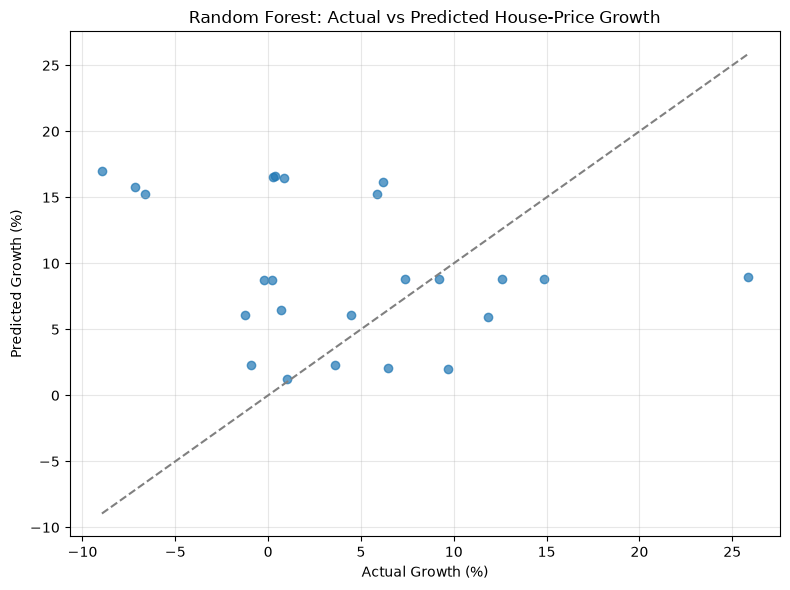

In [19]:
# Compare actual and predicted house-price growth.
results = test[["city", "year", "price_growth_pct"]].copy()
results["predicted_growth"] = rf_prediction

plt.figure(figsize=(8, 6))

plt.scatter(
    results["price_growth_pct"],
    results["predicted_growth"],
    alpha=0.7
)

# Reference line representing perfect predictions.
limits = [
    min(results["price_growth_pct"].min(), results["predicted_growth"].min()),
    max(results["price_growth_pct"].max(), results["predicted_growth"].max())
]

plt.plot(limits, limits, "--", color="gray")

plt.title("Random Forest: Actual vs Predicted House-Price Growth")
plt.xlabel("Actual Growth (%)")
plt.ylabel("Predicted Growth (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The actual-versus-predicted plot reveals substantial prediction errors, particularly for cities experiencing unusually strong price growth or price declines.

Random Forest frequently underpredicts large positive growth rates and overpredicts negative growth rates.

The model achieved an MAE of 9.23 percentage points, exceeding the baseline MAE of 6.53 percentage points.

Conclusion: The available economic indicators do not provide sufficient predictive information for reliable house-price growth forecasts over the 2023–2025 test period.

Potential limitations include the small dataset, changing economic conditions, and differences between regional housing markets.

Future improvements could include longer historical coverage, additional housing-market indicators, and time-series cross-validation. However, further model development should avoid repeatedly optimising against the existing test period.

In [20]:
# Collect predictions from all evaluated models.
predictions = {
    "Baseline": baseline_prediction,
    "Linear Regression": linear_prediction,
    "Ridge Regression": ridge_prediction,
    "Linear (No Cash Rate)": prediction_no_rates,
    "Random Forest": rf_prediction
}

# Compare model performance.
comparison = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    }
    for name, pred in predictions.items()
])

comparison = comparison.sort_values("MAE")

display(comparison.round(3))

,Model,MAE,RMSE,R2
0,Baseline,6.530,8.112,-0.160
3,Linear (No Cash Rate),6.842,8.152,-0.171
4,Random Forest,9.234,11.798,-1.453
2,Ridge Regression,16.566,18.023,-4.725
1,Linear Regression,20.167,21.651,-7.262


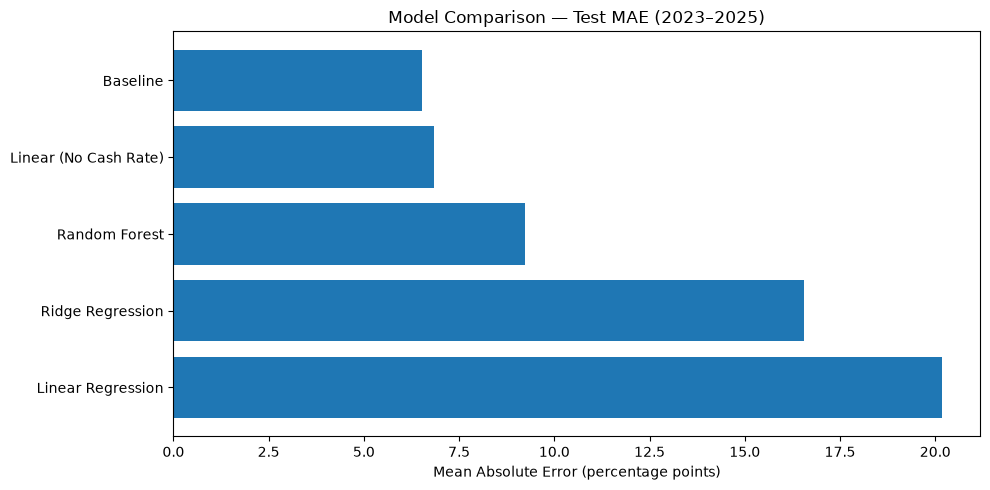

In [21]:
# Visualise test MAE for each model.
plt.figure(figsize=(10, 5))

plt.barh(comparison["Model"], comparison["MAE"])
plt.gca().invert_yaxis()

plt.title("Model Comparison — Test MAE (2023–2025)")
plt.xlabel("Mean Absolute Error (percentage points)")
plt.tight_layout()
plt.show()

We evaluated multiple regression approaches to predict annual house-price growth across Australia's eight capital cities using previous-year population growth, dwelling approvals, and RBA cash rates.

The historical-average baseline achieved the lowest test MAE of 6.53 percentage points, outperforming Linear Regression, Ridge Regression, and Random Forest.

The three-feature Linear Regression model performed particularly poorly, with an MAE of 20.17 and an R² of -7.262. Excluding the interest-rate feature reduced MAE to 6.84, suggesting that this variable contributed substantially to the model's prediction errors.

Key Findings

Interest-rate distribution shift: The testing period included cash rates substantially higher than those observed during training. This created difficulties for models that learned relationships under historically low interest rates.

Limited historical observations: The training dataset contained only 48 observations across six years and eight cities, limiting the reliability of estimated relationships.

Model complexity: Random Forest captured nonlinear relationships but did not outperform the baseline, demonstrating that more complex models do not necessarily improve predictive performance.

Housing-market complexity: Population growth, dwelling approvals, and borrowing costs alone were insufficient for reliable prediction of house-price growth during 2023–2025.

Limitations

The dataset contains relatively few independent historical years.

Relationships between economic indicators and house prices may change over time.

National interest rates are shared across cities, limiting independent variation.

Dwelling approvals measure intended construction rather than completed homes.

Median transaction prices can change because of the mix of properties sold, not only changes in underlying property values.

The test period was used for exploratory model comparisons, so these results should not be presented as an unbiased estimate after model selection.

Final Conclusion

The project demonstrates the challenges of predicting housing-market movements using a small dataset of economic indicators.

Although the machine learning models did not outperform the baseline, the analysis identified important issues involving limited data, changing economic conditions, and model generalisation.

The principal finding is that economically plausible predictors do not necessarily provide reliable forecasting performance, particularly when the future market differs substantially from historical observations.